# 2. Análisis con gráficas

## Un polinomio con dos ceros

### Método de la secante con los extremos p0=0 y p1=1

In [37]:
def P(x):
    return 230*x**4 + 18*x**3 + 9*x**2 -221*x - 9

def secante(P, p0, p1, TOL=1e-6, N0=50):
    historia = [p0,p1]
    i = 2
    q0 = P(p0)
    q1 = P(p1)

    while i <= N0:

        if q1 == q0:
            raise ZeroDivisionError(f"P(po) = P(p1): la secante es horizontal en los puntos {p0} y {p1}")
        p = p1- q1 * (p1 - p0) / (q1 - q0)
        historia.append(p)
        if abs(p - p1) < TOL:
            return historia
        i = i + 1
        p0 = p1; q0 = q1; p1 = p; q1 = P(p)
    raise RuntimeError(f"El método fracasó después de {N0} iteraciones")

secante(P,0,1)


[0,
 1,
 0.25,
 0.7737627651217597,
 -1.2854177835209222,
 0.5945955204028852,
 0.3946411046833955,
 -0.6693181355515856,
 0.04971439761607255,
 -0.020754150823816236,
 -0.04073533289637811,
 -0.04065922824320605,
 -0.04065928831557162]

### Método de Newton con el punto medio p0=0.5

In [ ]:
def P(x):
    return 230*x**4 + 18*x**3 + 9*x**2 -221*x - 9

def dP(x):
    return 230*4*x**3 + 18*3*x**2 + 9*2*x -221

def newton_raphson(P, dP, p0, TOL=1e-6, N0=50):
    historia = [p0]
    i = 1
    while i <= N0:
        d = dP(p0)
        if d == 0:
            raise ZeroDivisionError(f"P'(p0) = 0 en p0 = {p0}: la tangente es horizontal")
        p = p0 - P(p0)/d                          
        historia.append(p)             
        if abs(p - p0) < TOL:                        
            return historia
        i = i + 1
        p0 = p                         
    raise RuntimeError(f"El método fracasó después de {N0} iteraciones")

newton_raphson(P,dP,0.5)

[0.5,
 -0.7050898203592815,
 -0.3237911142304748,
 -0.06460313103057486,
 -0.04068615115195558,
 -0.04065928834533494,
 -0.040659288315758865]

### Gráfica preliminar antes de elegir los puntos iniciales

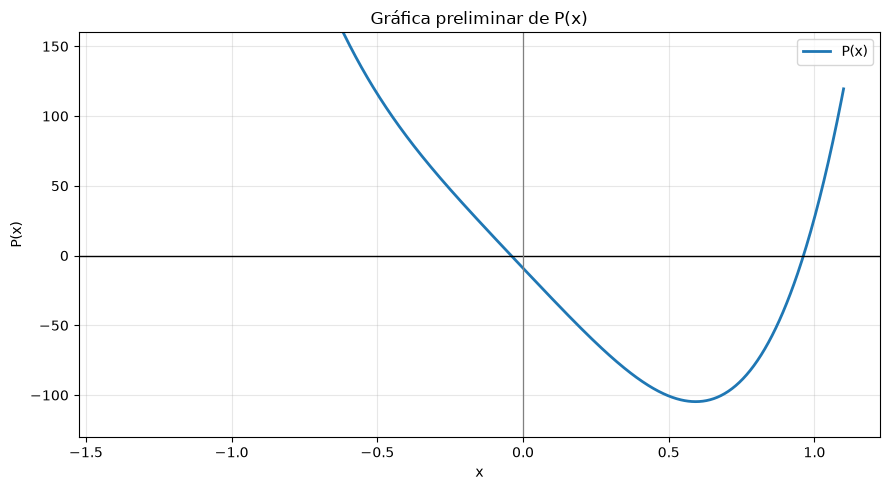

Secante con extremos:  -0.040659288
Newton con punto medio: -0.040659288


In [39]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-1.4, 1.1, 1000)
plt.figure(figsize=(9, 5))
plt.plot(x, P(x), label='P(x)', linewidth=2)
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='gray', linewidth=0.9)
plt.ylim(-130, 160)
plt.xlabel('x')
plt.ylabel('P(x)')
plt.title('Gráfica preliminar de P(x)')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('polinomio_preliminar.png', dpi=180)
plt.show()

h_sec = secante(P, 0, 1)
h_new = newton_raphson(P, dP, 0.5)
h_pos = newton_raphson(P, dP, 0.95)
print('Secante con extremos: ', f'{h_sec[-1]:.9f}')
print('Newton con punto medio:', f'{h_new[-1]:.9f}')

### Método de Newton con p0=0.9

In [40]:
newton_raphson(P,dP,0.9)

[0.9,
 0.9717887837996939,
 0.9625712797273669,
 0.96239847876793,
 0.9623984187505487]

### Grafique P en [-1.4,1.1], marque sus dos ceros y las aproximaciones p0,p1,...,p4 de la secante desde p0=0,p1=1, numeradas

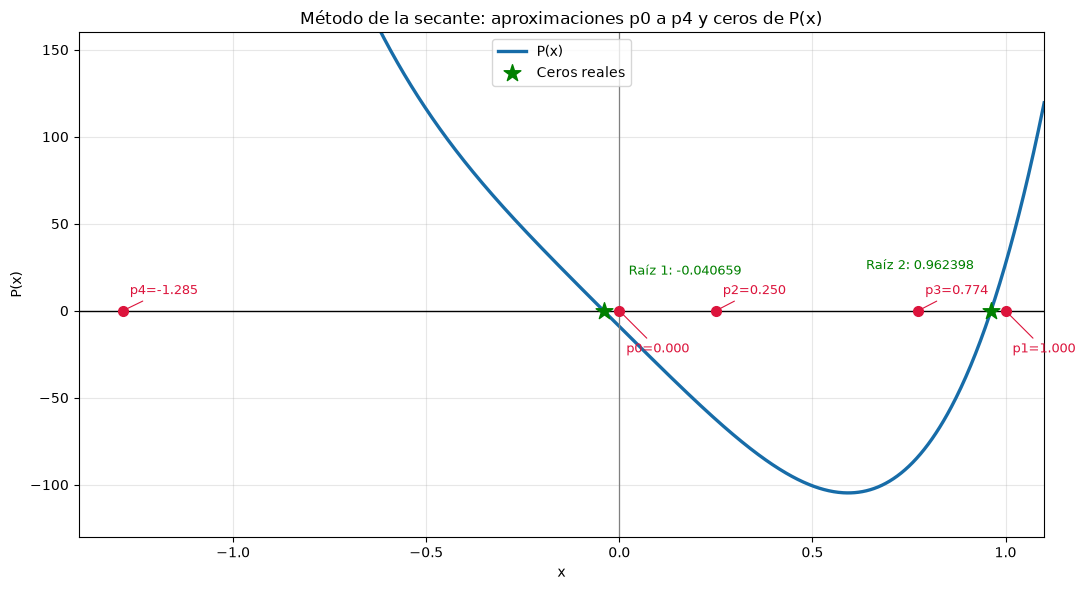

Primeras aproximaciones de la secante:
p0 = 0.000000000
p1 = 1.000000000
p2 = 0.250000000
p3 = 0.773762765
p4 = -1.285417784


In [41]:
raiz_neg = -0.04065928831575885
raiz_pos = 0.9623984187503846
plt.figure(figsize=(11, 6))
plt.plot(x, P(x), color='#176ca8', linewidth=2.4, label='P(x)')
plt.axhline(0, color='black', linewidth=1)
plt.axvline(0, color='gray', linewidth=0.9)
plt.scatter([raiz_neg, raiz_pos], [0, 0], color='green', marker='*', s=160, zorder=5, label='Ceros reales')
plt.annotate(f'Raíz 1: {raiz_neg:.6f}', (raiz_neg, 0), xytext=(18, 26), textcoords='offset points', color='green', fontsize=9)
plt.annotate(f'Raíz 2: {raiz_pos:.6f}', (raiz_pos, 0), xytext=(-90, 30), textcoords='offset points', color='green', fontsize=9)
for i, p in enumerate(h_sec[:5]):
    plt.plot(p, 0, 'o', color='crimson', markersize=7, zorder=6)
    offset = {0:(5,-30), 1:(5,-30), 2:(5,12), 3:(5,12), 4:(5,12)}[i]
    plt.annotate(f'p{i}={p:.3f}', (p,0), xytext=offset, textcoords='offset points', color='crimson', fontsize=9, arrowprops=dict(arrowstyle='-', color='crimson', lw=.8))
plt.xlim(-1.4,1.1)
plt.ylim(-130,160)
plt.xlabel('x')
plt.ylabel('P(x)')
plt.title('Método de la secante: aproximaciones p0 a p4 y ceros de P(x)')
plt.grid(alpha=.3)
plt.legend(loc='upper center')
plt.tight_layout()
plt.savefig('secante_polinomio_p0_p4.png', dpi=190)
plt.show()

print('Primeras aproximaciones de la secante:')
for i, p in enumerate(h_sec[:5]):
    print(f'p{i} = {p:.9f}')

### La función $f(x) = \ln(x^2 + 1) - e^ {0.4x} cos(\pi x)$ tiene un número infinito de ceros. Grafíquela en [-1,5].

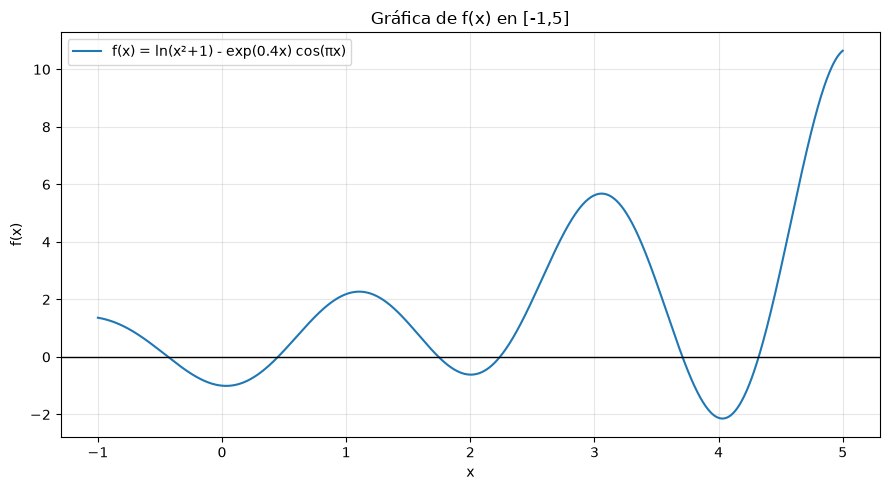

25.º cero positivo: 24.499887047 f(raíz)= -3.394102936482568e-07
Historial del cero 25:
0 24.400000000000
1 24.600000000000
2 24.495887402934
3 24.499791290017
4 24.499887203571
5 24.499887047440


In [42]:
def f(x):
    return np.log(x*x + 1) - np.exp(0.4*x)*np.cos(np.pi*x)

xs=np.linspace(-1, 5, 1200)
plt.figure(figsize=(9, 5))
plt.plot(xs, f(xs), label='f(x) = ln(x²+1) - exp(0.4x) cos(πx)')
plt.axhline(0, color='black', linewidth=1)
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Gráfica de f(x) en [-1,5]')
plt.grid(alpha=.3)
plt.legend()
plt.tight_layout()
plt.savefig('funcion_logaritmica_raices.png', dpi=180)
plt.show()

h25=secante(f, 24.4, 24.6)
print('25.º cero positivo:', f'{h25[-1]:.9f}', 'f(raíz)=', f(h25[-1]))
print('Historial del cero 25:')
for i,v in enumerate(h25): print(i, f'{v:.12f}')

## 3. Cuando no hay raíz

### Newton aplicado a $f(x) = e^x$

In [56]:
def f(x):
    return np.exp(x)

def df(x):
    return np.exp(x)

def newton_raphson(f, df, p0, TOL=1e-6, N0=50):
    historia = [p0]
    i = 1
    while i <= N0:
        d = df(p0)
        if d == 0:
            raise ZeroDivisionError(f"f'(p0) = 0 en p0 = {p0}: la tangente es horizontal")
        p = p0 - f(p0)/d                          
        historia.append(p)             
        if abs(f(p)) < TOL:     #Paso 4 modificado                   
            return historia
        i = i + 1
        p0 = p                         
    raise RuntimeError(f"El método fracasó después de {N0} iteraciones")


newton_raphson(f, df, 0)


[0,
 np.float64(-1.0),
 np.float64(-2.0),
 np.float64(-3.0),
 np.float64(-4.0),
 np.float64(-5.0),
 np.float64(-6.0),
 np.float64(-7.0),
 np.float64(-8.0),
 np.float64(-9.0),
 np.float64(-10.0),
 np.float64(-11.0),
 np.float64(-12.0),
 np.float64(-13.0),
 np.float64(-14.0)]

### Señal de un sensor

In [57]:

def s(t):
    return np.exp(-t/2) * (1.2 + np.cos(2*t))

def ds(t):
    return np.exp(-t/2) * (
        -0.5 * (1.2 + np.cos(2*t))
        - 2 * np.sin(2*t)
    )

for t0 in [0, 2, 3, 4]:
    historia = newton_raphson(s, ds, t0)
    t = historia[-1]

    print(f"\nPunto inicial: {t0}")
    print(f"Valor devuelto: {t:.9f}")
    print(f"s(t): {s(t):.9e}")
    print(f"s(t-0.01): {s(t-0.01):.9e}")
    print(f"s(t+0.01): {s(t+0.01):.9e}")



Punto inicial: 0
Valor devuelto: 49.130306590
s(t): 1.193053392e-11
s(t-0.01): 1.166320167e-11
s(t+0.01): 1.220040692e-11

Punto inicial: 2
Valor devuelto: 49.130306590
s(t): 1.193053392e-11
s(t-0.01): 1.166320167e-11
s(t+0.01): 1.220040692e-11

Punto inicial: 3
Valor devuelto: 184.224760906
s(t): 5.602521851e-41
s(t-0.01): 5.477940181e-41
s(t+0.01): 5.728228010e-41

Punto inicial: 4
Valor devuelto: 26.721542141
s(t): 3.161740690e-07
s(t-0.01): 3.169352103e-07
s(t+0.01): 3.160393702e-07


### Grafica lado a lado en [0,12]

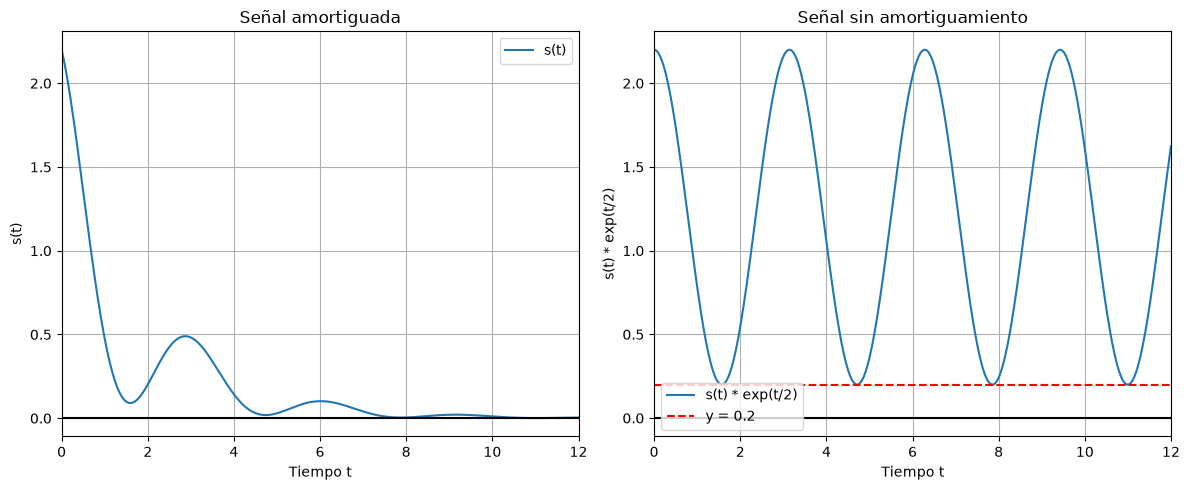

In [58]:
t = np.linspace(0, 12, 1000)

def s(t):
    return np.exp(-t/2) * (1.2 + np.cos(2*t))

# Crear dos gráficas lado a lado
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Primera gráfica: señal original
ax[0].plot(t, s(t), label="s(t)")
ax[0].axhline(0, color="black")
ax[0].set_title("Señal amortiguada")
ax[0].set_xlabel("Tiempo t")
ax[0].set_ylabel("s(t)")
ax[0].set_xlim(0, 12)
ax[0].grid()
ax[0].legend()

# Segunda gráfica: señal sin amortiguamiento
y = s(t) * np.exp(t/2)

ax[1].plot(t, y, label="s(t) * exp(t/2)")
ax[1].axhline(0.2, color="red", linestyle="--",
              label="y = 0.2")
ax[1].axhline(0, color="black")
ax[1].set_title("Señal sin amortiguamiento")
ax[1].set_xlabel("Tiempo t")
ax[1].set_ylabel("s(t) * exp(t/2)")
ax[1].set_xlim(0, 12)
ax[1].grid()
ax[1].legend()

plt.tight_layout()
plt.savefig("grafica_sensor.png", dpi=300)
plt.show()

### Newton en SciPy (scipy.optimize.newton)

In [59]:
import numpy as np
from scipy.optimize import newton

raiz, info = newton(np.exp, 0, fprime=np.exp, maxiter=1000, full_output=True)
print(raiz, info.converged, np.exp(raiz))

-746.0 True 0.0


## 4. Convergencia en una gráfica

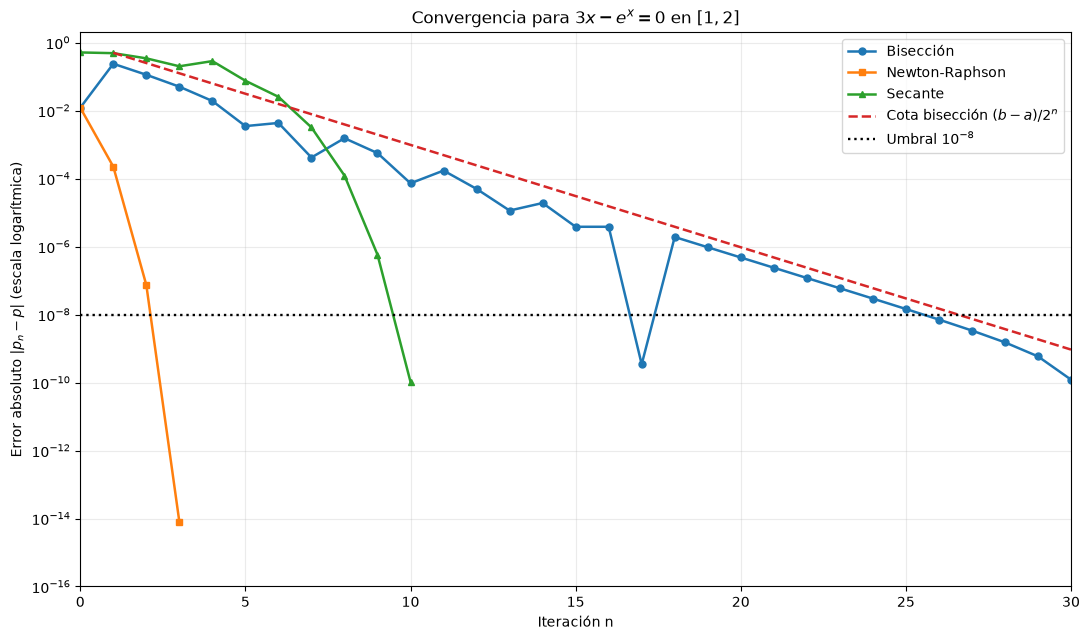

Raíz de referencia: 1.512134551657842


In [66]:
def f(x):
    return 3*x - np.exp(x)

def df(x):
    return 3 - np.exp(x)

def biseccion(f, a, b, TOL, N0): 
    
    FA = f(a)
    historia = []
    i = 1
    while i <= N0:
        p = a+(b-a)/2                                     
        FP = f(p)
        historia.append(p)                       
        if FP == 0 or (b-a)/2 < TOL:                          
            return historia
        i = i + 1
        if FA * FP > 0:
            a = p
            FA = FP                                    
        else:
            b = p                                     
    raise RuntimeError(f"fracasó después de {N0} iteraciones")

# Raíz de referencia con secante y tolerancia 1e-14
historia_referencia = secante(f, 1, 2, TOL=1e-14, N0=100)
raiz = historia_referencia[-1]

hist_bis = biseccion(f, 1, 2, TOL=1e-14,N0=50)
hist_new = newton_raphson(f, df, 1.5, TOL=1e-14, N0=50)
hist_sec = secante(f, 1, 2, TOL=1e-14, N0=50)

# Valor cero no se dibuja en escala logarítmica
def graficar_errores(historia, etiqueta, marcador):
    errores = [abs(pn-raiz) for pn in historia]
    xs = [n for n, error in enumerate(errores) if error>0]
    ys = [error for error in errores if error>0]
    plt.semilogy(xs, ys, marker=marcador, label=etiqueta, linewidth=1.8, markersize=5)
    return errores

plt.figure(figsize=(11,6.5))
err_bis=graficar_errores(hist_bis, 'Bisección', 'o')
err_new=graficar_errores(hist_new, 'Newton-Raphson', 's')
err_sec=graficar_errores(hist_sec, 'Secante', '^')

# p1 de bisección es el primer punto medio, por eso n comienza en 1
n = np.arange(1, 31)
plt.semilogy(n, (2-1)/2.0**n, '--', label=r'Cota bisección $(b-a)/2^n$', linewidth=1.8)
plt.axhline(1e-8, linestyle=':', color='black', linewidth=1.7, label=r'Umbral $10^{-8}$')
plt.xlabel('Iteración n')
plt.ylabel(r'Error absoluto $|p_n-p|$ (escala logarítmica)')
plt.title(r'Convergencia para $3x-e^x=0$ en $[1,2]$')
plt.grid(True, which='both', alpha=0.25)
plt.legend()
plt.xlim(0,30)
plt.ylim(1e-16, 2)
plt.tight_layout()
plt.savefig('convergencia.png', dpi=220, bbox_inches='tight')
plt.show()

print(f'Raíz de referencia: {raiz:.15f}')
